In [21]:
# ============================================================
#  فایل پیش‌بینی: predict_fuel.ipynb
#  وظیفه: بارگذاری مدل ذخیره‌شده و پیش‌بینی مصرف برای مسافت جدید
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import joblib

In [23]:
# ---------- ۱. بارگذاری مدل ----------
MODEL_PATH = "model/fuel_model.pkl"
model = joblib.load(MODEL_PATH)

print("=" * 50)
print("مدل با موفقیت بارگذاری شد.")
print("=" * 50)
print(f"شیب (a): {model.coef_[0]:.4f}")
print(f"عرض از مبدأ (b): {model.intercept_:.4f}")
print("=" * 50)

مدل با موفقیت بارگذاری شد.
شیب (a): 0.0800
عرض از مبدأ (b): -0.0000


In [24]:
# ---------- ۲. پیش‌بینی برای ورودی جدید ----------
new_distance = 500
forecasted_consumption = model.predict([[new_distance]])[0]

print(f"مسافت: {new_distance} کیلومتر")
print(f"مصرف پیش‌بینی‌شده: {forecasted_consumption:.2f} لیتر")
print("=" * 50)

مسافت: 500 کیلومتر
مصرف پیش‌بینی‌شده: 40.00 لیتر


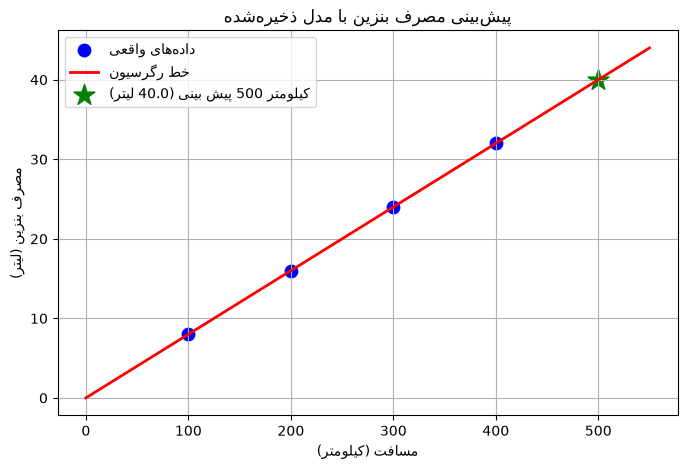

In [25]:
#---------- ۳. رسم نمودار همراه با نقطه پیش‌بینی ----------
# داده‌های اصلی فقط برای رسم نمودار
X = np.array([[100], [200], [300], [400]])
y = np.array([8, 16, 24, 32])

plt.figure(figsize=(8, 5))

plt.scatter(X, y, color='blue', s=80, label='داده‌های واقعی')

X_line = np.linspace(0, 550, 100).reshape(-1, 1)
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label='خط رگرسیون')

plt.scatter([new_distance], [forecasted_consumption], color='green',
            marker='*', s=250,
            label = f'کیلومتر {new_distance} پیش بینی ({forecasted_consumption:.1f} لیتر)')

plt.xlabel('مسافت (کیلومتر)')
plt.ylabel('مصرف بنزین (لیتر)')
plt.title('پیش‌بینی مصرف بنزین با مدل ذخیره‌شده')
plt.legend()
plt.grid(True)
fig = plt.gcf()

In [26]:
PLOT_PATH = "results/fuel_prediction_plot.png"
fig.savefig(PLOT_PATH, dpi=150, bbox_inches='tight')
print(f"نمودار پیش‌بینی در فایل «{PLOT_PATH}» ذخیره شد.")

plt.show()

نمودار پیش‌بینی در فایل «results/fuel_prediction_plot.png» ذخیره شد.
